In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q kagglehub nibabel monai scikit-learn seaborn scipy tqdm

import os, glob, time, random, shutil, warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F

from scipy.ndimage import zoom
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc
from scipy.stats import pearsonr, spearmanr
from monai.losses import DiceCELoss

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Устройство:", device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 74.8 MB/s eta 0:00:00
Устройство: cuda
Tesla T4


In [2]:
BASE_DIR = '/content/drive/MyDrive/diplom'

DATA_NII = f'{BASE_DIR}/lits_original'
IMG_DIR = f'{DATA_NII}/images/images'
MSK_DIR = f'{DATA_NII}/masks/masks'

TEST_DIR = f'{BASE_DIR}/3d-liver-segmentation'
CKPT_DIR = f'{BASE_DIR}/checkpoints_improved'
CACHE_DIR = f'{BASE_DIR}/cache_improved_3d'
RESULTS_DIR = f'{BASE_DIR}/results_improved'

for d in [TEST_DIR, CKPT_DIR, CACHE_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print("LiTS:", os.path.isdir(IMG_DIR), os.path.isdir(MSK_DIR))
print("Результаты:", RESULTS_DIR)

LiTS: True True
Результаты: /content/drive/MyDrive/diplom/results_improved


In [3]:
import kagglehub

download_path = kagglehub.dataset_download(
    'prathamgrover/3d-liver-segmentation'
)

print("Загружен:", download_path)

for item in os.listdir(download_path):
    src = os.path.join(download_path, item)
    dst = os.path.join(TEST_DIR, item)

    if os.path.isdir(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
    elif not os.path.exists(dst):
        shutil.copy2(src, dst)

print("Второй датасет:", TEST_DIR)
print("Элементов:", len(os.listdir(TEST_DIR)))

100%|██████████| 2.16G/2.16G [01:45<00:00, 21.9MB/s]

Extracting files...


Загружен: /root/.cache/kagglehub/datasets/prathamgrover/3d-liver-segmentation/versions/1
Второй датасет: /content/drive/MyDrive/diplom/3d-liver-segmentation
Элементов: 1


In [4]:
volumes = sorted(glob.glob(f'{IMG_DIR}/volume-*.nii*'))
masks = sorted(glob.glob(f'{MSK_DIR}/segmentation-*.nii*'))

mask_map = {
    os.path.basename(p).replace('segmentation-', '').replace('.nii.gz', '').replace('.nii', ''): p
    for p in masks
}

pairs = []
for v in volumes:
    name = os.path.basename(v).replace('volume-', '').replace('.nii.gz', '').replace('.nii', '')
    if name in mask_map:
        pairs.append((v, mask_map[name]))

print("КТ:", len(volumes))
print("Маски:", len(masks))
print("Пар:", len(pairs))

assert len(pairs) > 0, "Не найдены пары. Проверь IMG_DIR и MSK_DIR."

КТ: 131
Маски: 131
Пар: 131


In [6]:
import os
import glob
import nibabel as nib
import numpy as np
from tqdm.auto import tqdm

DATA_NII = "/content/drive/MyDrive/diplom/lits_original"

all_nii = glob.glob(
    os.path.join(DATA_NII, "**", "*.nii"), recursive=True
)
all_nii_gz = glob.glob(
    os.path.join(DATA_NII, "**", "*.nii.gz"), recursive=True
)
all_files = sorted(set(all_nii + all_nii_gz))

images = {}
masks = {}

for p in all_files:
    name = os.path.basename(p)

    if name.startswith("volume-"):
        case_id = name[len("volume-"):]
    elif name.startswith("segmentation-"):
        case_id = name[len("segmentation-"):]
    else:
        continue

    case_id = case_id.replace(".nii.gz", "").replace(".nii", "")

    if name.startswith("volume-"):
        images[case_id] = p
    else:
        masks[case_id] = p

common_ids = sorted(
    set(images) & set(masks),
    key=lambda x: int(x) if x.isdigit() else x
)

print("Всего файлов изображений:", len(images))
print("Всего файлов масок:", len(masks))
print("Совпадающих пар:", len(common_ids))

valid_pairs = []

for case_id in tqdm(common_ids, desc="Проверка LiTS"):
    vp, mp = images[case_id], masks[case_id]

    try:
        vi = nib.load(vp)
        mi = nib.load(mp)

        if vi.shape != mi.shape:
            print(f"Размеры не совпадают: {case_id}")
            continue

        mask = np.asarray(mi.dataobj)
        liver_voxels = int(np.count_nonzero(mask > 0))

        if liver_voxels < 50_000:
            print(f"Малая маска: {case_id}, {liver_voxels}")
            continue

        valid_pairs.append((vp, mp))

    except Exception as e:
        print(f"Ошибка {case_id}: {type(e).__name__}: {e}")

pairs = valid_pairs

print(f"\nВалидных пар LiTS: {len(pairs)}")
if pairs:
    print("Пример изображения:", pairs[0][0])
    print("Пример маски:", pairs[0][1])
else:
    print("Проверь структуру папок и наличие файлов.")

Всего файлов изображений: 131
Всего файлов масок: 131
Совпадающих пар: 131


Проверка LiTS:   0%|          | 0/131 [00:00<?, ?it/s]


Валидных пар LiTS: 131
Пример изображения: /content/drive/MyDrive/diplom/lits_original/images/images/volume-0.nii
Пример маски: /content/drive/MyDrive/diplom/lits_original/masks/masks/segmentation-0.nii


In [7]:
TARGET_SHAPE = (128, 128, 128)
TARGET_SPACING = (1.0, 1.0, 1.0)

def preprocess_ct(vol):
    vol = np.clip(vol, -100, 200)
    return ((vol + 100) / 300).astype(np.float32)

def resize_volume(vol, target_shape, order):
    factors = [t / s for t, s in zip(target_shape, vol.shape)]
    return zoom(vol, factors, order=order).astype(np.float32)

def load_case(v_path, m_path):
    vi = nib.load(v_path)
    mi = nib.load(m_path)

    v = vi.get_fdata(dtype=np.float32)
    m = mi.get_fdata(dtype=np.float32)

    v = resize_volume(v, TARGET_SHAPE, order=1)
    m = resize_volume(m, TARGET_SHAPE, order=0)

    v = preprocess_ct(v)
    m = (m > 0.5).astype(np.float32)

    return v, m

v, m = load_case(*pairs[0])
print("КТ:", v.shape, v.min(), v.max())
print("Маска:", m.shape, np.unique(m))

КТ: (128, 128, 128) 0.0 1.0
Маска: (128, 128, 128) [0. 1.]


In [8]:
for vp, mp in tqdm(pairs, desc="Кэширование"):
    name = os.path.basename(vp).replace('.nii.gz', '').replace('.nii', '')
    cv = f'{CACHE_DIR}/{name}_v.npy'
    cm = f'{CACHE_DIR}/{name}_m.npy'

    if os.path.exists(cv) and os.path.exists(cm):
        continue

    v, m = load_case(vp, mp)
    np.save(cv, v)
    np.save(cm, m)

print("Кэш:", CACHE_DIR)
print("Файлов:", len(glob.glob(f'{CACHE_DIR}/*.npy')))

Кэширование:   0%|          | 0/131 [00:00<?, ?it/s]

Кэш: /content/drive/MyDrive/diplom/cache_improved_3d
Файлов: 262


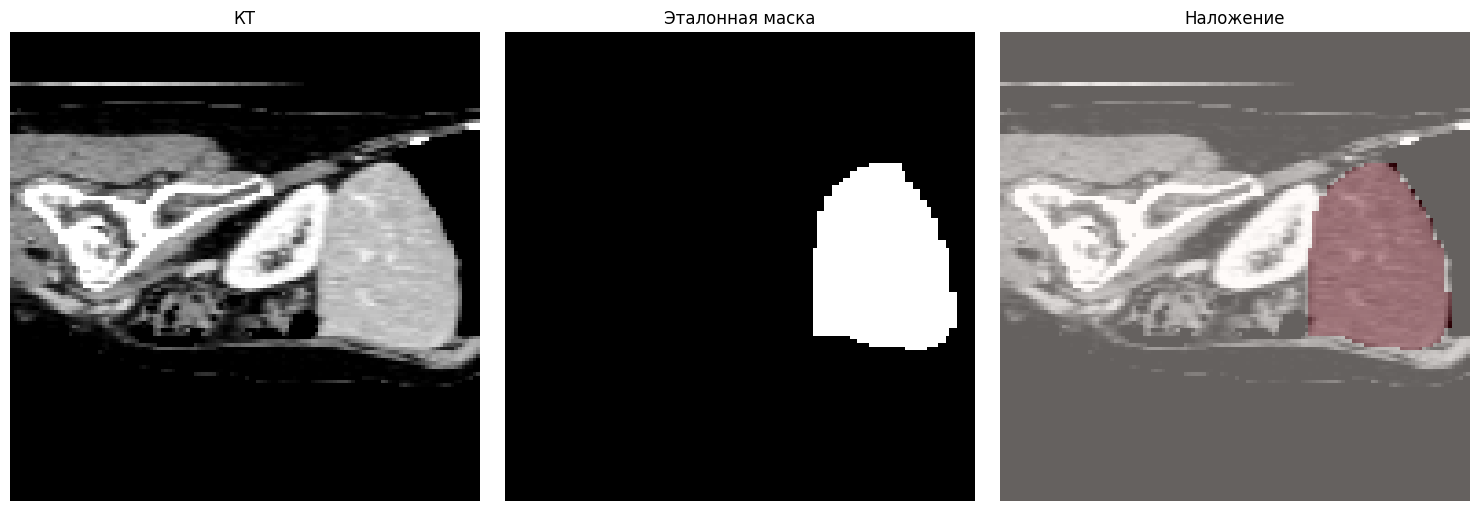

In [9]:
sample_name = os.path.basename(pairs[0][0]).replace('.nii.gz', '').replace('.nii', '')
v = np.load(f'{CACHE_DIR}/{sample_name}_v.npy')
m = np.load(f'{CACHE_DIR}/{sample_name}_m.npy')

z = int(np.argmax(m.sum(axis=(1, 2))))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(v[z], cmap='gray')
ax[0].set_title('КТ')
ax[1].imshow(m[z], cmap='gray')
ax[1].set_title('Эталонная маска')
ax[2].imshow(v[z], cmap='gray')
ax[2].imshow(m[z], cmap='Reds', alpha=.4)
ax[2].set_title('Наложение')

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

In [16]:
train_pairs, val_pairs = train_test_split(
    pairs, test_size=0.2, random_state=SEED
)

print("Train:", len(train_pairs))
print("Validation:", len(val_pairs))


def cache_name(path):
    return os.path.basename(path).replace(".nii.gz", "").replace(".nii", "")


class LiverDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        vp, mp = self.pairs[idx]
        name = cache_name(vp)

        v = np.load(os.path.join(CACHE_DIR, f"{name}_v.npy"))
        m = np.load(os.path.join(CACHE_DIR, f"{name}_m.npy"))

        v = v.astype(np.float32, copy=False)
        m = (m > 0).astype(np.float32, copy=False)

        if self.augment:
            for axis in range(3):
                if random.random() < 0.5:
                    v = np.flip(v, axis=axis)
                    m = np.flip(m, axis=axis)

            if random.random() < 0.3:
                v = np.clip(
                    v + np.random.uniform(-0.08, 0.08), 0, 1
                )

            if random.random() < 0.3:
                v = np.clip(
                    v * np.random.uniform(0.9, 1.1), 0, 1
                )

        v = np.ascontiguousarray(v[None])
        m = np.ascontiguousarray(m[None])

        return torch.from_numpy(v), torch.from_numpy(m)


train_ds = LiverDataset(train_pairs, augment=True)
val_ds = LiverDataset(val_pairs, augment=False)

train_loader = DataLoader(
    train_ds,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Загрузчики готовы.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train: 104
Validation: 27
Загрузчики готовы.
Train batches: 104
Validation batches: 27


In [17]:
class ResidualBlock3D(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.1):
        super().__init__()

        self.conv1 = nn.Conv3d(
            in_ch, out_ch, kernel_size=3, padding=1, bias=False
        )
        self.norm1 = nn.InstanceNorm3d(out_ch, affine=True)

        self.conv2 = nn.Conv3d(
            out_ch, out_ch, kernel_size=3, padding=1, bias=False
        )
        self.norm2 = nn.InstanceNorm3d(out_ch, affine=True)

        self.act = nn.LeakyReLU(0.1, inplace=True)
        self.drop = nn.Dropout3d(dropout)

        self.skip = (
            nn.Conv3d(in_ch, out_ch, kernel_size=1, bias=False)
            if in_ch != out_ch else nn.Identity()
        )

    def forward(self, x):
        residual = self.skip(x)
        y = self.act(self.norm1(self.conv1(x)))
        y = self.drop(y)
        y = self.norm2(self.conv2(y))
        return self.act(y + residual)


class UNet3D(nn.Module):
    def __init__(self, base=16):
        super().__init__()

        self.enc1 = ResidualBlock3D(1, base)
        self.enc2 = ResidualBlock3D(base, base * 2)
        self.enc3 = ResidualBlock3D(base * 2, base * 4)

        self.pool = nn.MaxPool3d(2)
        self.bottleneck = ResidualBlock3D(base * 4, base * 8)

        self.up3 = nn.ConvTranspose3d(base * 8, base * 4, 2, 2)
        self.dec3 = ResidualBlock3D(base * 8, base * 4)

        self.up2 = nn.ConvTranspose3d(base * 4, base * 2, 2, 2)
        self.dec2 = ResidualBlock3D(base * 4, base * 2)

        self.up1 = nn.ConvTranspose3d(base * 2, base, 2, 2)
        self.dec1 = ResidualBlock3D(base * 2, base)

        self.out = nn.Conv3d(base, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)


model = UNet3D(base=16).to(device)

print("Параметров:", sum(p.numel() for p in model.parameters()))

CKPT_PATH = os.path.join(CKPT_DIR, "best_3d_unet.pth")
LAST_PATH = os.path.join(CKPT_DIR, "last_3d_unet.pth")

criterion = DiceCELoss(
    sigmoid=True,
    lambda_dice=1.0,
    lambda_ce=1.0,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
)

amp_enabled = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "lr": [],
}

start_epoch = 0
best_dice = 0.0
early_stop = 0

RESUME_TRAINING = False

if RESUME_TRAINING and os.path.exists(LAST_PATH):
    ckpt = torch.load(
        LAST_PATH,
        map_location=device,
        weights_only=False,
    )

    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])

    start_epoch = ckpt["epoch"] + 1
    best_dice = ckpt.get("best_dice", 0.0)
    history = ckpt.get("history", history)
    early_stop = ckpt.get("early_stop", 0)

    if "scaler" in ckpt:
        scaler.load_state_dict(ckpt["scaler"])

    if "scheduler" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler"])

    print("Продолжение с эпохи:", start_epoch + 1)

else:
    print("Обучение с нуля.")

print("AMP:", amp_enabled)
print("Device:", device)

Параметров: 1422785
Обучение с нуля.
AMP: True
Device: cuda


In [18]:
EPOCHS = 50
PATIENCE = 10
MIN_DELTA = 1e-4


def dice_score(pred, target):
    pred = pred.bool()
    target = target.bool()

    inter = (pred & target).sum().float()

    return (2 * inter + 1e-6) / (
        pred.sum() + target.sum() + 1e-6
    )


t0 = time.time()

for epoch in range(start_epoch, EPOCHS):
    model.train()
    train_losses = []

    for img, mask in tqdm(
        train_loader,
        desc=f"Train {epoch + 1}/{EPOCHS}",
    ):
        img = img.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=amp_enabled,
        ):
            logits = model(img)
            loss = criterion(logits, mask)

        scaler.scale(loss).backward()

        if amp_enabled:
            scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        train_losses.append(loss.detach().item())

    model.eval()
    val_losses = []
    val_dices = []

    with torch.inference_mode():
        for img, mask in tqdm(
            val_loader,
            desc="Validation",
            leave=False,
        ):
            img = img.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            with torch.autocast(
                device_type=device.type,
                enabled=amp_enabled,
            ):
                logits = model(img)
                loss = criterion(logits, mask)

            pred = torch.sigmoid(logits) > 0.5

            val_losses.append(loss.item())
            val_dices.append(dice_score(pred, mask).item())

    if not train_losses or not val_losses:
        raise RuntimeError(
            "Пустой train_loader или val_loader. Проверь пары и кэш."
        )

    tr_loss = float(np.mean(train_losses))
    vl_loss = float(np.mean(val_losses))
    vd = float(np.mean(val_dices))

    scheduler.step(vd)
    lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["val_dice"].append(vd)
    history["lr"].append(lr)

    improved = vd > best_dice + MIN_DELTA

    if improved:
        best_dice = vd
        early_stop = 0
    else:
        early_stop += 1

    state = {
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "scheduler": scheduler.state_dict(),
        "best_dice": best_dice,
        "history": history,
        "early_stop": early_stop,
    }

    torch.save(state, LAST_PATH)

    if improved:
        torch.save(state, CKPT_PATH)
        status = " | Сохранена лучшая модель"
    else:
        status = ""

    print(
        f"Эпоха {epoch + 1}/{EPOCHS} | "
        f"Train={tr_loss:.4f} | "
        f"Val={vl_loss:.4f} | "
        f"Dice={vd:.4f} | "
        f"Best={best_dice:.4f} | "
        f"LR={lr:.1e}{status}"
    )

    if early_stop >= PATIENCE:
        print(f"Early stopping: {PATIENCE} эпох без улучшения.")
        break

print(f"\nЛучший Validation Dice: {best_dice:.4f}")
print(f"Время обучения: {(time.time() - t0) / 60:.1f} мин")
print("Лучшая модель:", CKPT_PATH)
print("Последний checkpoint:", LAST_PATH)

Train 1/50:   0%|          | 0/104 [00:00<?, ?it/s]

Validation:   0%|          | 0/27 [00:00<?, ?it/s]

Эпоха 1/50 | Train=1.4315 | Val=1.2865 | Dice=0.6745 | Best=0.6745 | LR=1.0e-04 | Сохранена лучшая модель


Train 2/50:   0%|          | 0/104 [00:00<?, ?it/s]

Validation:   0%|          | 0/27 [00:00<?, ?it/s]

Эпоха 2/50 | Train=1.1856 | Val=1.0030 | Dice=0.8071 | Best=0.8071 | LR=1.0e-04 | Сохранена лучшая модель


... (140 outputs left out)

Эпоха 49/50 | Train=0.0698 | Val=0.0797 | Dice=0.9386 | Best=0.9463 | LR=5.0e-05


Train 50/50:   0%|          | 0/104 [00:00<?, ?it/s]

Validation:   0%|          | 0/27 [00:00<?, ?it/s]

Эпоха 50/50 | Train=0.0658 | Val=0.0725 | Dice=0.9435 | Best=0.9463 | LR=5.0e-05

Лучший Validation Dice: 0.9463
Время обучения: 23.2 мин
Лучшая модель: /content/drive/MyDrive/diplom/checkpoints_improved/best_3d_unet.pth
Последний checkpoint: /content/drive/MyDrive/diplom/checkpoints_improved/last_3d_unet.pth


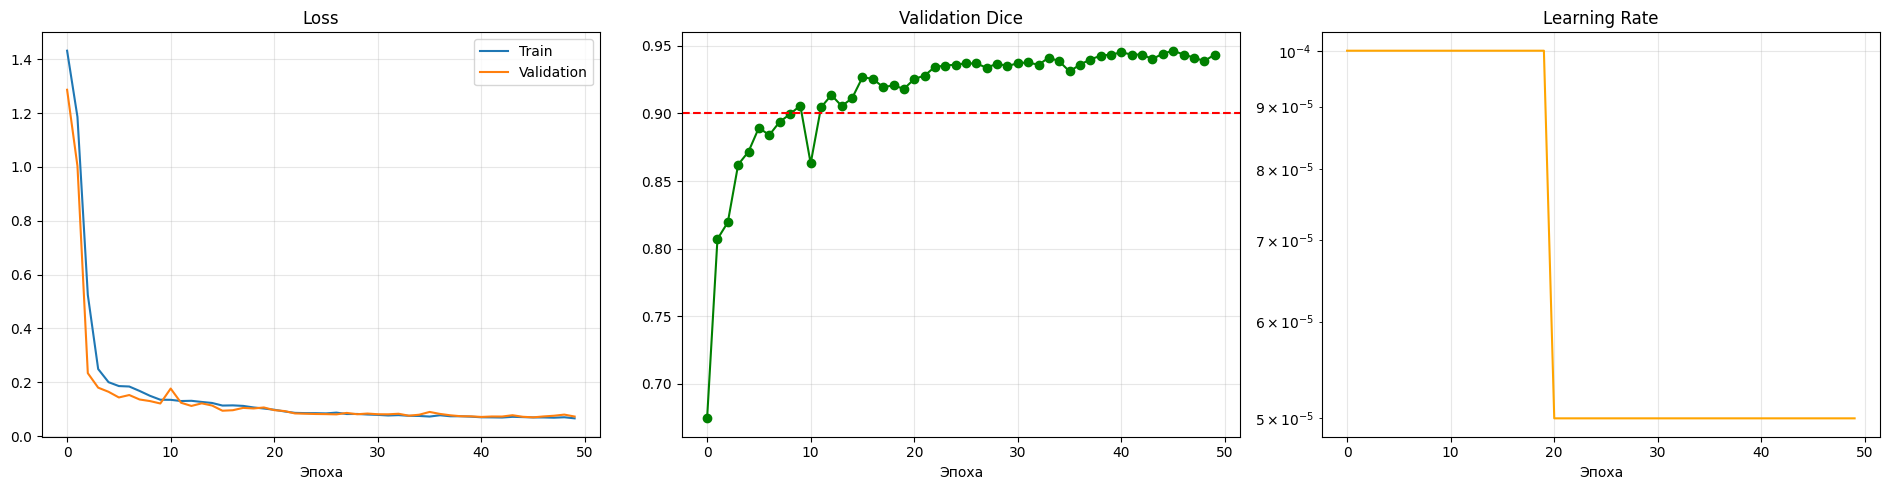

Разрыв Val − Train: 0.0067


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Эпоха')
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].plot(history['val_dice'], color='green', marker='o')
axes[1].axhline(.9, color='red', linestyle='--')
axes[1].set_title('Validation Dice')
axes[1].set_xlabel('Эпоха')
axes[1].grid(alpha=.3)

axes[2].plot(history['lr'], color='orange')
axes[2].set_title('Learning Rate')
axes[2].set_yscale('log')
axes[2].set_xlabel('Эпоха')
axes[2].grid(alpha=.3)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/training_curves.png', dpi=150)
plt.show()

if history['train_loss']:
    gap = history['val_loss'][-1] - history['train_loss'][-1]
    print(f"Разрыв Val − Train: {gap:.4f}")

Confusion matrix:   0%|          | 0/27 [00:00<?, ?it/s]

Precision: 0.9413
Recall:    0.9506
F1:        0.9460
IoU:       0.8975
Accuracy:  0.9970


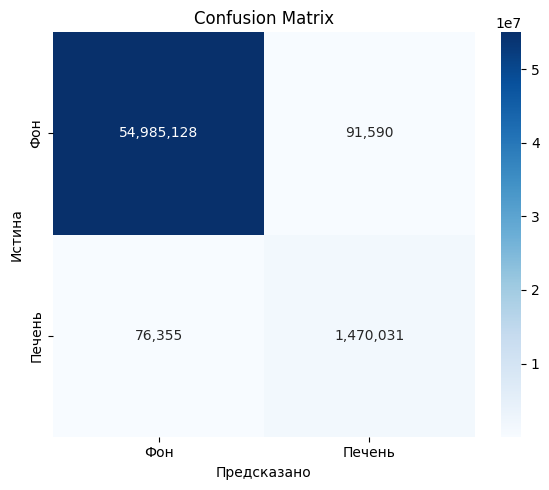

In [20]:
ckpt = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(ckpt['model'])
model.eval()

all_pred, all_true = [], []

with torch.inference_mode():
    for img, mask in tqdm(val_loader, desc="Confusion matrix"):
        img = img.to(device)
        pred = (torch.sigmoid(model(img)) > .5).cpu().numpy().ravel()
        all_pred.append(pred)
        all_true.append(mask.numpy().ravel())

all_pred = np.concatenate(all_pred)
all_true = np.concatenate(all_true).astype(np.uint8)

cm = confusion_matrix(all_true, all_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

precision = tp / (tp + fp + 1e-8)
recall = tp / (tp + fn + 1e-8)
f1 = 2 * precision * recall / (precision + recall + 1e-8)
iou = tp / (tp + fp + fn + 1e-8)
accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-8)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1:        {f1:.4f}")
print(f"IoU:       {iou:.4f}")
print(f"Accuracy:  {accuracy:.4f}")

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt=',d', cmap='Blues',
    xticklabels=['Фон', 'Печень'],
    yticklabels=['Фон', 'Печень']
)
plt.xlabel('Предсказано')
plt.ylabel('Истина')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/confusion_matrix.png', dpi=150)
plt.show()

ROC:   0%|          | 0/27 [00:00<?, ?it/s]

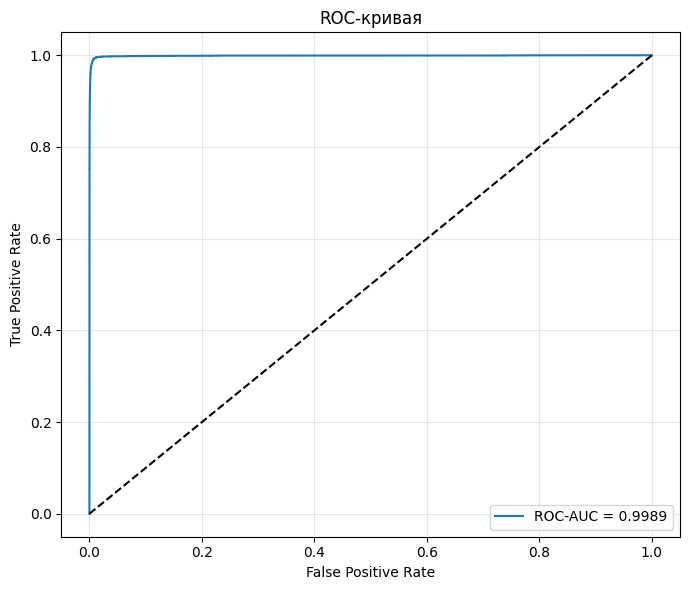

In [21]:
rng = np.random.default_rng(SEED)
roc_probs, roc_true = [], []

with torch.inference_mode():
    for img, mask in tqdm(val_loader, desc="ROC"):
        img = img.to(device)
        probs = torch.sigmoid(model(img)).cpu().numpy().ravel()
        true = mask.numpy().ravel()

        n = min(10000, len(true))
        ids = rng.choice(len(true), size=n, replace=False)

        roc_probs.append(probs[ids])
        roc_true.append(true[ids])

roc_probs = np.concatenate(roc_probs)
roc_true = np.concatenate(roc_true).astype(np.uint8)

fpr, tpr, _ = roc_curve(roc_true, roc_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/roc_curve.png', dpi=150)
plt.show()

Оценка пациентов:   0%|          | 0/27 [00:00<?, ?it/s]

Пациент                    Dice    Pred мл    True мл   Ошибка %
volume-55                0.9168       73.1       69.9       4.59
volume-40                0.9582      135.8      133.4       1.79
volume-19                0.9649       55.8       55.6       0.33
volume-31                0.9320      109.8       99.1      10.83
volume-115               0.9480       31.9       30.6       4.14
volume-56                0.9365       53.3       57.2       6.80
volume-69                0.9502       48.7       52.1       6.65
volume-105               0.9567       29.2       28.1       3.80
volume-81                0.9360       51.4       54.0       4.91
volume-26                0.9527       28.5       27.6       3.04
volume-95                0.8985       36.9       38.1       3.08
volume-27                0.9569       30.8       30.8       0.02
volume-64                0.9625       61.1       61.9       1.36
volume-4                 0.9351       41.6       45.3       8.19
volume-97                

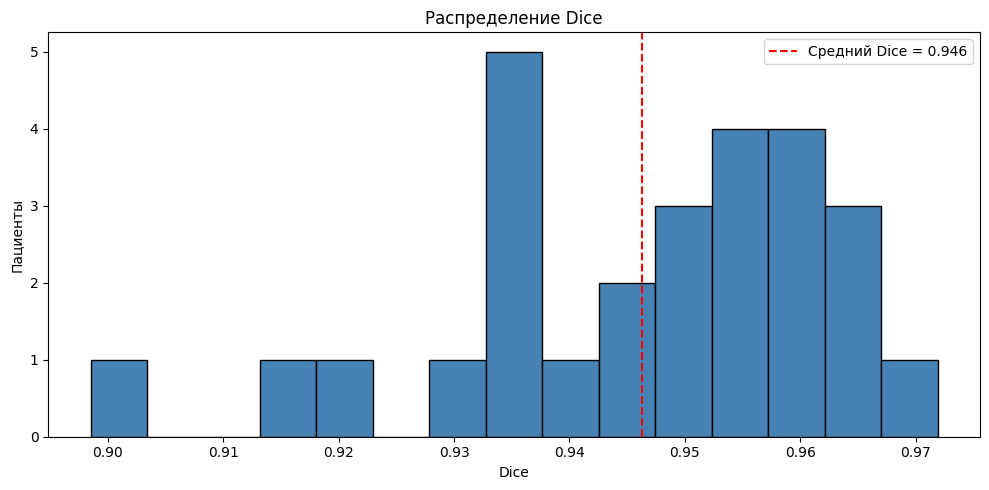

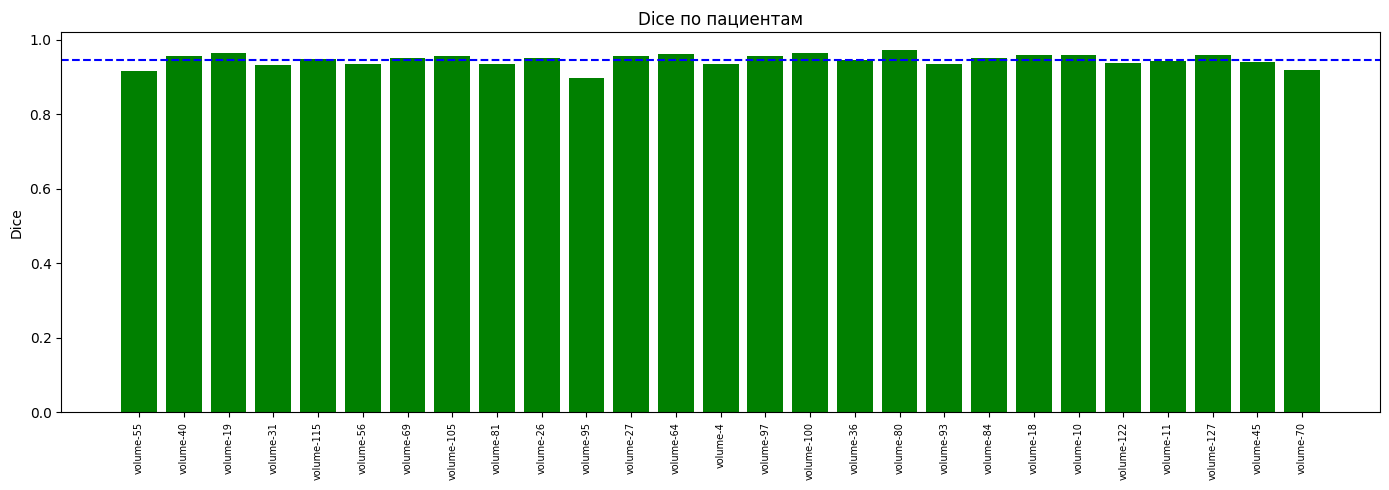

In [22]:
def volume_ml(mask, spacing=(1, 1, 1)):
    return float((mask > .5).sum() * np.prod(spacing) / 1000)

def dice_np(pred, true):
    pred, true = pred > .5, true > .5
    return 2 * np.logical_and(pred, true).sum() / (
        pred.sum() + true.sum() + 1e-8
    )

rows = []

with torch.inference_mode():
    for vp, mp in tqdm(val_pairs, desc="Оценка пациентов"):
        name = cache_name(vp)
        v = np.load(f'{CACHE_DIR}/{name}_v.npy')
        m = np.load(f'{CACHE_DIR}/{name}_m.npy')

        x = torch.from_numpy(v.copy())[None, None].float().to(device)
        pred = (torch.sigmoid(model(x))[0, 0] > .5).cpu().numpy()

        d = dice_np(pred, m)
        v_pred = volume_ml(pred)
        v_true = volume_ml(m)
        err = abs(v_pred - v_true) / v_true * 100 if v_true > 0 else np.nan

        rows.append((name, d, v_pred, v_true, err))

print(f"{'Пациент':<22} {'Dice':>8} {'Pred мл':>10} {'True мл':>10} {'Ошибка %':>10}")
for r in rows:
    print(f"{r[0]:<22} {r[1]:>8.4f} {r[2]:>10.1f} {r[3]:>10.1f} {r[4]:>10.2f}")

dices = np.array([r[1] for r in rows])
print("Средний Dice:", round(float(dices.mean()), 4))
print("Минимальный Dice:", round(float(dices.min()), 4))
print("Максимальный Dice:", round(float(dices.max()), 4))

plt.figure(figsize=(10, 5))
plt.hist(dices, bins=15, color='steelblue', edgecolor='black')
plt.axvline(dices.mean(), color='red', linestyle='--',
            label=f'Средний Dice = {dices.mean():.3f}')
plt.xlabel('Dice')
plt.ylabel('Пациенты')
plt.title('Распределение Dice')
plt.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/dice_histogram.png', dpi=150)
plt.show()

plt.figure(figsize=(14, 5))
plt.bar(range(len(rows)), dices,
        color=['green' if d >= .85 else 'orange' if d >= .7 else 'red'
               for d in dices])
plt.xticks(range(len(rows)), [r[0] for r in rows], rotation=90, fontsize=7)
plt.axhline(dices.mean(), color='blue', linestyle='--')
plt.ylabel('Dice')
plt.title('Dice по пациентам')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/dice_per_patient.png', dpi=150)
plt.show()

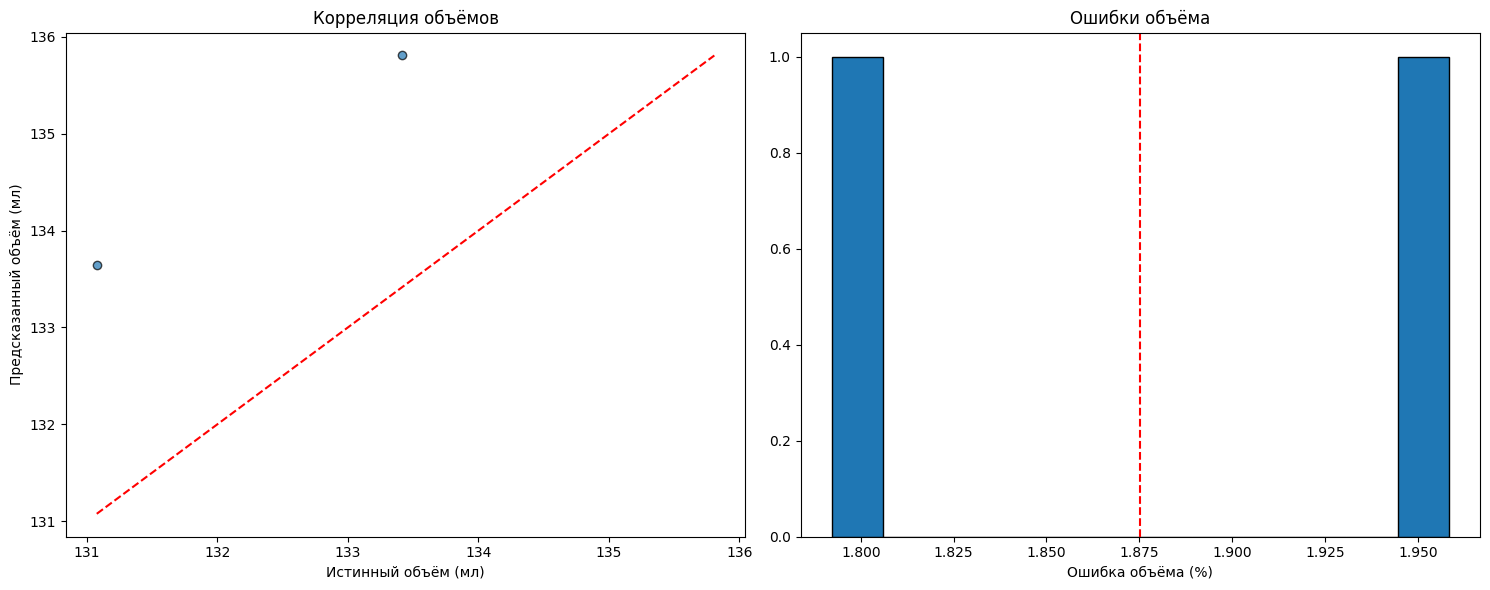

Pearson: PearsonRResult(statistic=np.float64(1.0), pvalue=np.float64(1.0))
Spearman: SignificanceResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(nan))
MAE, мл: 2.478999999999999
RMSE, мл: 2.4805614283867263
Средняя ошибка, %: 1.8752730963818767


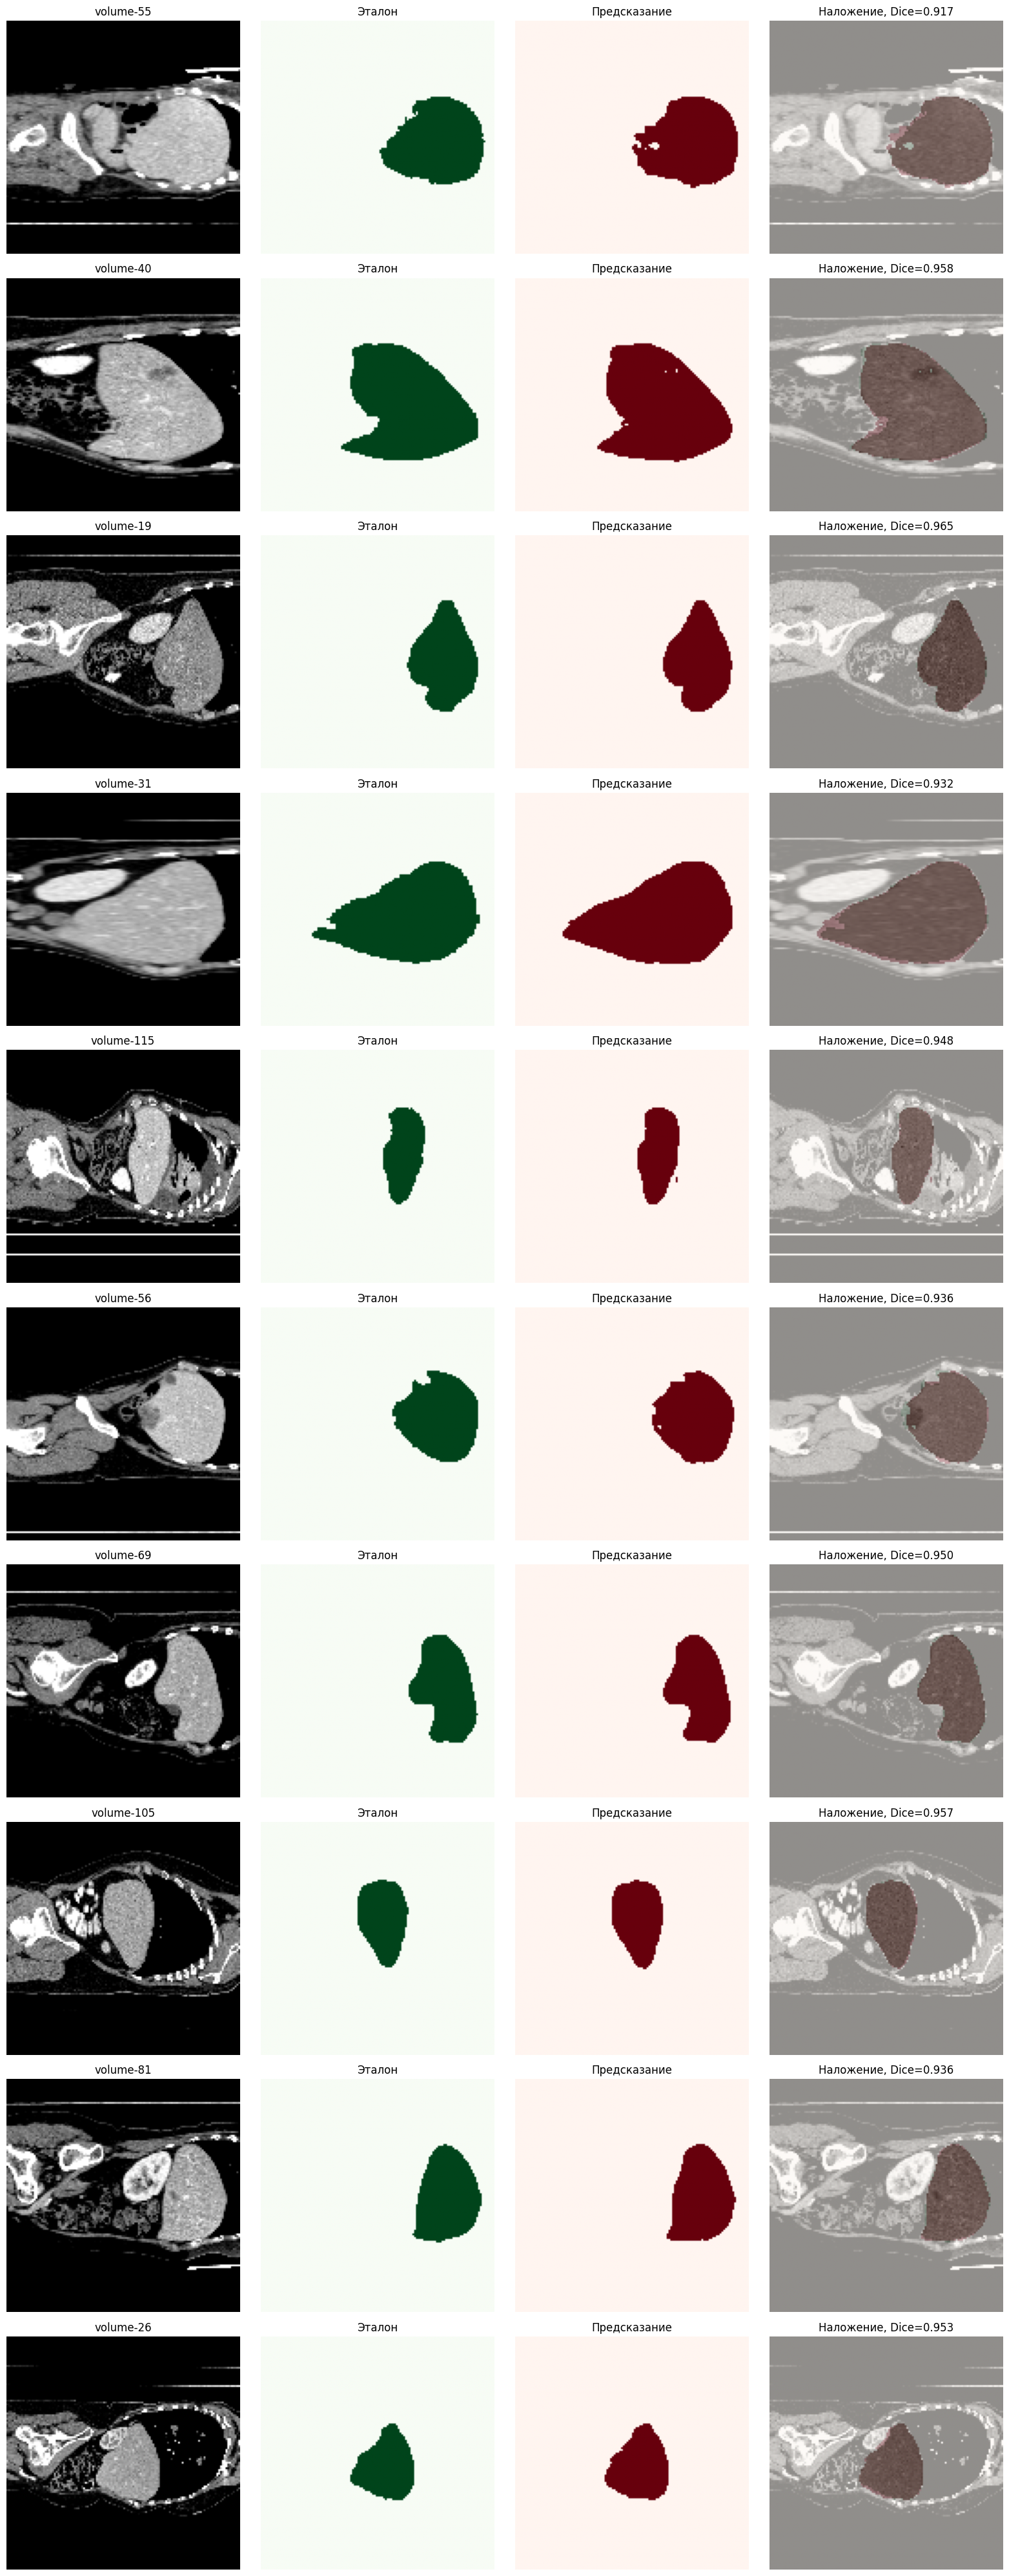

In [23]:
valid = [r for r in rows if r[3] > 100 and np.isfinite(r[4])]
vp = np.array([r[2] for r in valid])
vt = np.array([r[3] for r in valid])
errors = np.abs(vp - vt) / vt * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

if len(valid):
    axes[0].scatter(vt, vp, edgecolors='black', alpha=.7)
    lims = [min(vt.min(), vp.min()), max(vt.max(), vp.max())]
    axes[0].plot(lims, lims, 'r--')
    axes[0].set_xlabel('Истинный объём (мл)')
    axes[0].set_ylabel('Предсказанный объём (мл)')
    axes[0].set_title('Корреляция объёмов')

    axes[1].hist(errors, bins=12, edgecolor='black')
    axes[1].axvline(errors.mean(), color='red', linestyle='--')
    axes[1].set_xlabel('Ошибка объёма (%)')
    axes[1].set_title('Ошибки объёма')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/volume_correlation.png', dpi=150)
plt.show()

if len(valid) >= 2:
    print("Pearson:", pearsonr(vt, vp))
    print("Spearman:", spearmanr(vt, vp))
    print("MAE, мл:", np.mean(np.abs(vp - vt)))
    print("RMSE, мл:", np.sqrt(np.mean((vp - vt)**2)))
    print("Средняя ошибка, %:", errors.mean())

n_show = min(10, len(val_pairs))
fig, axes = plt.subplots(n_show, 4, figsize=(16, 4*n_show))
if n_show == 1:
    axes = axes[None, :]

with torch.inference_mode():
    for i, (vp_path, mp_path) in enumerate(val_pairs[:n_show]):
        name = cache_name(vp_path)
        v = np.load(f'{CACHE_DIR}/{name}_v.npy')
        m = np.load(f'{CACHE_DIR}/{name}_m.npy')

        pred = (torch.sigmoid(
            model(torch.from_numpy(v.copy())[None, None].float().to(device))
        )[0, 0] > .5).cpu().numpy()

        z = int(np.argmax(m.sum(axis=(1, 2))))
        d = dice_np(pred, m)

        axes[i, 0].imshow(v[z], cmap='gray')
        axes[i, 0].set_title(name)
        axes[i, 1].imshow(m[z], cmap='Greens')
        axes[i, 1].set_title('Эталон')
        axes[i, 2].imshow(pred[z], cmap='Reds')
        axes[i, 2].set_title('Предсказание')
        axes[i, 3].imshow(v[z], cmap='gray')
        axes[i, 3].imshow(m[z], cmap='Greens', alpha=.35)
        axes[i, 3].imshow(pred[z], cmap='Reds', alpha=.35)
        axes[i, 3].set_title(f'Наложение, Dice={d:.3f}')

        for a in axes[i]:
            a.axis('off')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/visualization_10_patients.png', dpi=120)
plt.show()

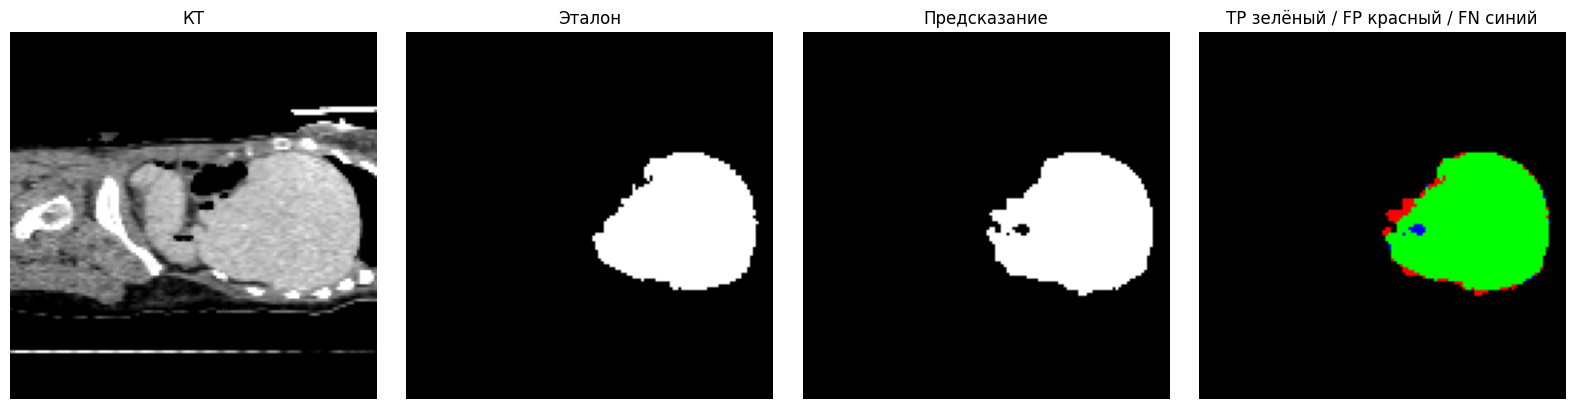

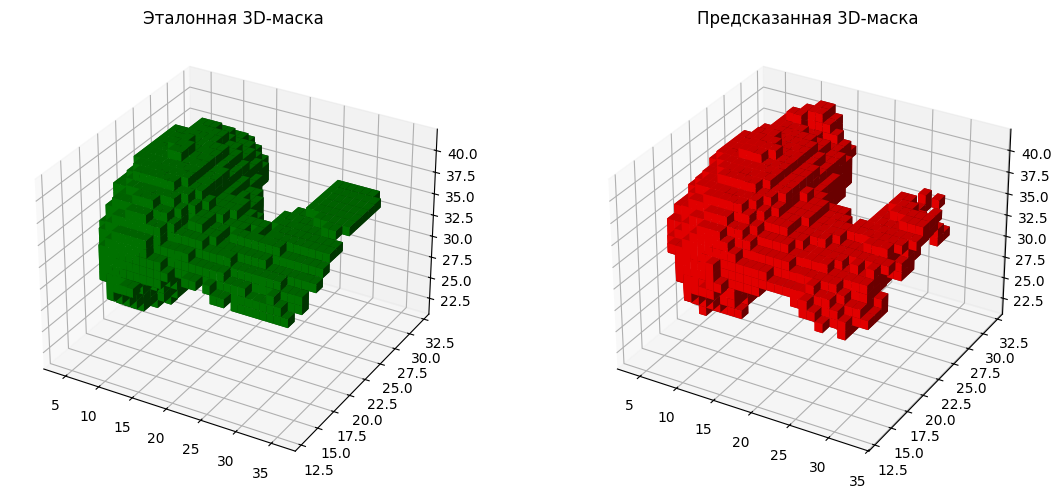

In [24]:
from mpl_toolkits.mplot3d import Axes3D

TARGET_CASE = os.path.basename(val_pairs[0][0])
name = cache_name(TARGET_CASE)

v = np.load(f'{CACHE_DIR}/{name}_v.npy')
gt = np.load(f'{CACHE_DIR}/{name}_m.npy') > .5

with torch.inference_mode():
    pred = (torch.sigmoid(
        model(torch.from_numpy(v.copy())[None, None].float().to(device))
    )[0, 0] > .5).cpu().numpy()

z = int(np.argmax(gt.sum(axis=(1, 2))))
tp = gt[z] & pred[z]
fp = ~gt[z] & pred[z]
fn = gt[z] & ~pred[z]

error = np.zeros((*gt[z].shape, 3), dtype=np.uint8)
error[tp] = [0, 255, 0]
error[fp] = [255, 0, 0]
error[fn] = [0, 0, 255]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(v[z], cmap='gray')
axes[0].set_title('КТ')
axes[1].imshow(gt[z], cmap='gray')
axes[1].set_title('Эталон')
axes[2].imshow(pred[z], cmap='gray')
axes[2].set_title('Предсказание')
axes[3].imshow(error)
axes[3].set_title('TP зелёный / FP красный / FN синий')

for a in axes:
    a.axis('off')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/error_map.png', dpi=150)
plt.show()

step = 3
gt_vis = gt[::step, ::step, ::step]
pred_vis = pred[::step, ::step, ::step]

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121, projection='3d')
ax1.voxels(gt_vis, facecolors='green', edgecolor='none')
ax1.set_title('Эталонная 3D-маска')

ax2 = fig.add_subplot(122, projection='3d')
ax2.voxels(pred_vis, facecolors='red', edgecolor='none')
ax2.set_title('Предсказанная 3D-маска')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/3d_visualization.png', dpi=120)
plt.show()

In [26]:
import os
import glob

external_files = sorted(
    glob.glob(f"{TEST_DIR}/**/*.nii", recursive=True)
    + glob.glob(f"{TEST_DIR}/**/*.nii.gz", recursive=True)
)

print("Путь:", TEST_DIR)
print("Всего NIfTI-файлов:", len(external_files))
print("\nПервые 50 файлов:")

for p in external_files[:50]:
    print(os.path.relpath(p, TEST_DIR))

print("\nПодпапки датасета:")
for root, dirs, files in os.walk(TEST_DIR):
    level = root.replace(TEST_DIR, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:5]:
            print("  " * (level + 1) + f)

Путь: /content/drive/MyDrive/diplom/3d-liver-segmentation
Всего NIfTI-файлов: 246

Первые 50 файлов:
Task03_Liver_rs/imagesTr/liver_0.nii
Task03_Liver_rs/imagesTr/liver_1.nii
Task03_Liver_rs/imagesTr/liver_10.nii
Task03_Liver_rs/imagesTr/liver_101.nii
Task03_Liver_rs/imagesTr/liver_102.nii
Task03_Liver_rs/imagesTr/liver_104.nii
Task03_Liver_rs/imagesTr/liver_105.nii
Task03_Liver_rs/imagesTr/liver_106.nii
Task03_Liver_rs/imagesTr/liver_107.nii
Task03_Liver_rs/imagesTr/liver_108.nii
Task03_Liver_rs/imagesTr/liver_109.nii
Task03_Liver_rs/imagesTr/liver_11.nii
Task03_Liver_rs/imagesTr/liver_110.nii
Task03_Liver_rs/imagesTr/liver_111.nii
Task03_Liver_rs/imagesTr/liver_112.nii
Task03_Liver_rs/imagesTr/liver_113.nii
Task03_Liver_rs/imagesTr/liver_114.nii
Task03_Liver_rs/imagesTr/liver_115.nii
Task03_Liver_rs/imagesTr/liver_116.nii
Task03_Liver_rs/imagesTr/liver_117.nii
Task03_Liver_rs/imagesTr/liver_118.nii
Task03_Liver_rs/imagesTr/liver_119.nii
Task03_Liver_rs/imagesTr/liver_12.nii
Task03_Li

In [27]:
import os
import glob
import numpy as np
import nibabel as nib
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
from tqdm.auto import tqdm

EXTERNAL_DIR = os.path.join(TEST_DIR, "Task03_Liver_rs")
EXTERNAL_IMG_DIR = os.path.join(EXTERNAL_DIR, "imagesTr")
EXTERNAL_MASK_DIR = os.path.join(EXTERNAL_DIR, "labelsTr")

assert os.path.isdir(EXTERNAL_IMG_DIR), f"Нет папки: {EXTERNAL_IMG_DIR}"
assert os.path.isdir(EXTERNAL_MASK_DIR), f"Нет папки: {EXTERNAL_MASK_DIR}"

ext_images = sorted(glob.glob(f"{EXTERNAL_IMG_DIR}/*.nii*"))
ext_masks = sorted(glob.glob(f"{EXTERNAL_MASK_DIR}/*.nii*"))

def file_id(path):
    name = os.path.basename(path)
    if name.endswith(".nii.gz"):
        name = name[:-7]
    elif name.endswith(".nii"):
        name = name[:-4]
    return name

mask_map = {file_id(p): p for p in ext_masks}
external_pairs = [
    (p, mask_map[file_id(p)])
    for p in ext_images
    if file_id(p) in mask_map
]

print("Изображений:", len(ext_images))
print("Масок:", len(ext_masks))
print("Совпадающих пар:", len(external_pairs))

assert external_pairs, "Не удалось сопоставить КТ и маски."

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model"])
model.eval()

def resize_to_training_shape(arr, order):
    factors = [
        t / s for t, s in zip(TARGET_SHAPE, arr.shape)
    ]
    return zoom(arr, factors, order=order).astype(np.float32)

def preprocess_external(img_path, mask_path):
    img_nii = nib.load(img_path)
    mask_nii = nib.load(mask_path)

    img = img_nii.get_fdata(dtype=np.float32)
    mask = mask_nii.get_fdata(dtype=np.float32)

    if img.shape != mask.shape:
        raise ValueError(
            f"Размеры не совпадают: {img.shape} и {mask.shape}"
        )

    img = np.clip(img, -100, 200)
    img = (img + 100) / 300
    img = resize_to_training_shape(img, order=1)
    mask = resize_to_training_shape(mask, order=0)

    mask = (mask > 0).astype(np.uint8)

    return img, mask

def binary_metrics(pred, true):
    pred = pred.astype(bool)
    true = true.astype(bool)

    tp = np.logical_and(pred, true).sum()
    fp = np.logical_and(pred, ~true).sum()
    fn = np.logical_and(~pred, true).sum()

    dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)

    return dice, iou, precision, recall

external_rows = []
external_examples = []

for img_path, mask_path in tqdm(
    external_pairs, desc="Независимый тест"
):
    try:
        img, true_mask = preprocess_external(img_path, mask_path)

        x = torch.from_numpy(img.copy())[None, None].to(device)

        with torch.inference_mode():
            with torch.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                logits = model(x)

            pred = (
                torch.sigmoid(logits)[0, 0] > 0.5
            ).cpu().numpy()

        dice, iou, precision, recall = binary_metrics(
            pred, true_mask
        )

        external_rows.append({
            "case": file_id(img_path),
            "Dice": dice,
            "IoU": iou,
            "Precision": precision,
            "Recall": recall,
            "True_voxels": int(true_mask.sum()),
            "Pred_voxels": int(pred.sum()),
        })

        if len(external_examples) < 6:
            external_examples.append(
                (file_id(img_path), img, true_mask, pred)
            )

    except Exception as e:
        print(f"Ошибка {file_id(img_path)}: {e}")

assert external_rows, "Ни одного объёма не удалось оценить."

external_df = pd.DataFrame(external_rows)
display(external_df.round(4))

print("\nСРЕДНИЕ МЕТРИКИ НЕЗАВИСИМОГО ТЕСТА")
for metric in ["Dice", "IoU", "Precision", "Recall"]:
    print(
        f"{metric}: {external_df[metric].mean():.4f} "
        f"+/- {external_df[metric].std():.4f}"
    )

external_df.to_csv(
    f"{RESULTS_DIR}/external_test_metrics.csv",
    index=False
)

print("\nРезультаты сохранены в:", RESULTS_DIR)

Изображений: 123
Масок: 123
Совпадающих пар: 123


Независимый тест:   0%|          | 0/123 [00:00<?, ?it/s]

,case,Dice,IoU,Precision,Recall,True_voxels,Pred_voxels
0,liver_0,0.9510,0.9066,0.9674,0.9351,59421,57435
1,liver_1,0.9502,0.9051,0.9651,0.9358,42301,41018
2,liver_10,0.9547,0.9134,0.9515,0.9580,45598,45909
3,liver_101,0.9591,0.9214,0.9519,0.9664,79478,80688
4,liver_102,0.9606,0.9243,0.9613,0.9600,59727,59641
...,...,...,...,...,...,...,...
118,liver_93,0.9299,0.8690,0.9478,0.9127,52767,50812
119,liver_94,0.8843,0.7926,0.8017,0.9860,25788,31717
120,liver_95,0.9074,0.8306,0.8994,0.9156,38134,38821
121,liver_98,0.9422,0.8908,0.9305,0.9543,50384,51672



СРЕДНИЕ МЕТРИКИ НЕЗАВИСИМОГО ТЕСТА
Dice: 0.9438 +/- 0.0197
IoU: 0.8941 +/- 0.0333
Precision: 0.9336 +/- 0.0371
Recall: 0.9554 +/- 0.0192

Результаты сохранены в: /content/drive/MyDrive/diplom/results_improved


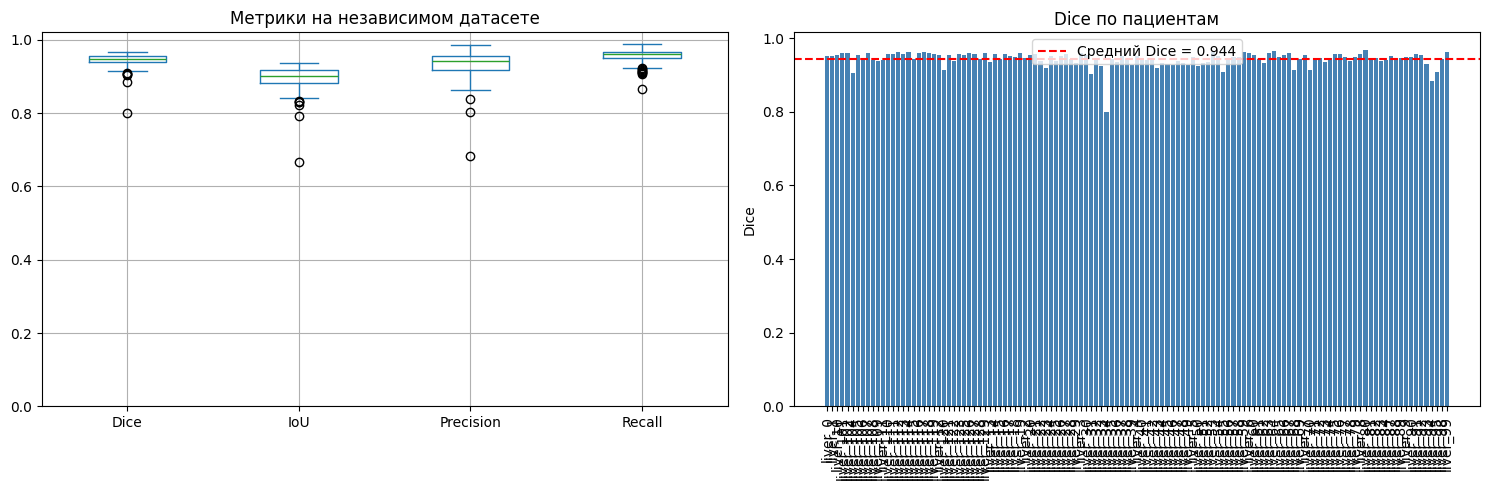

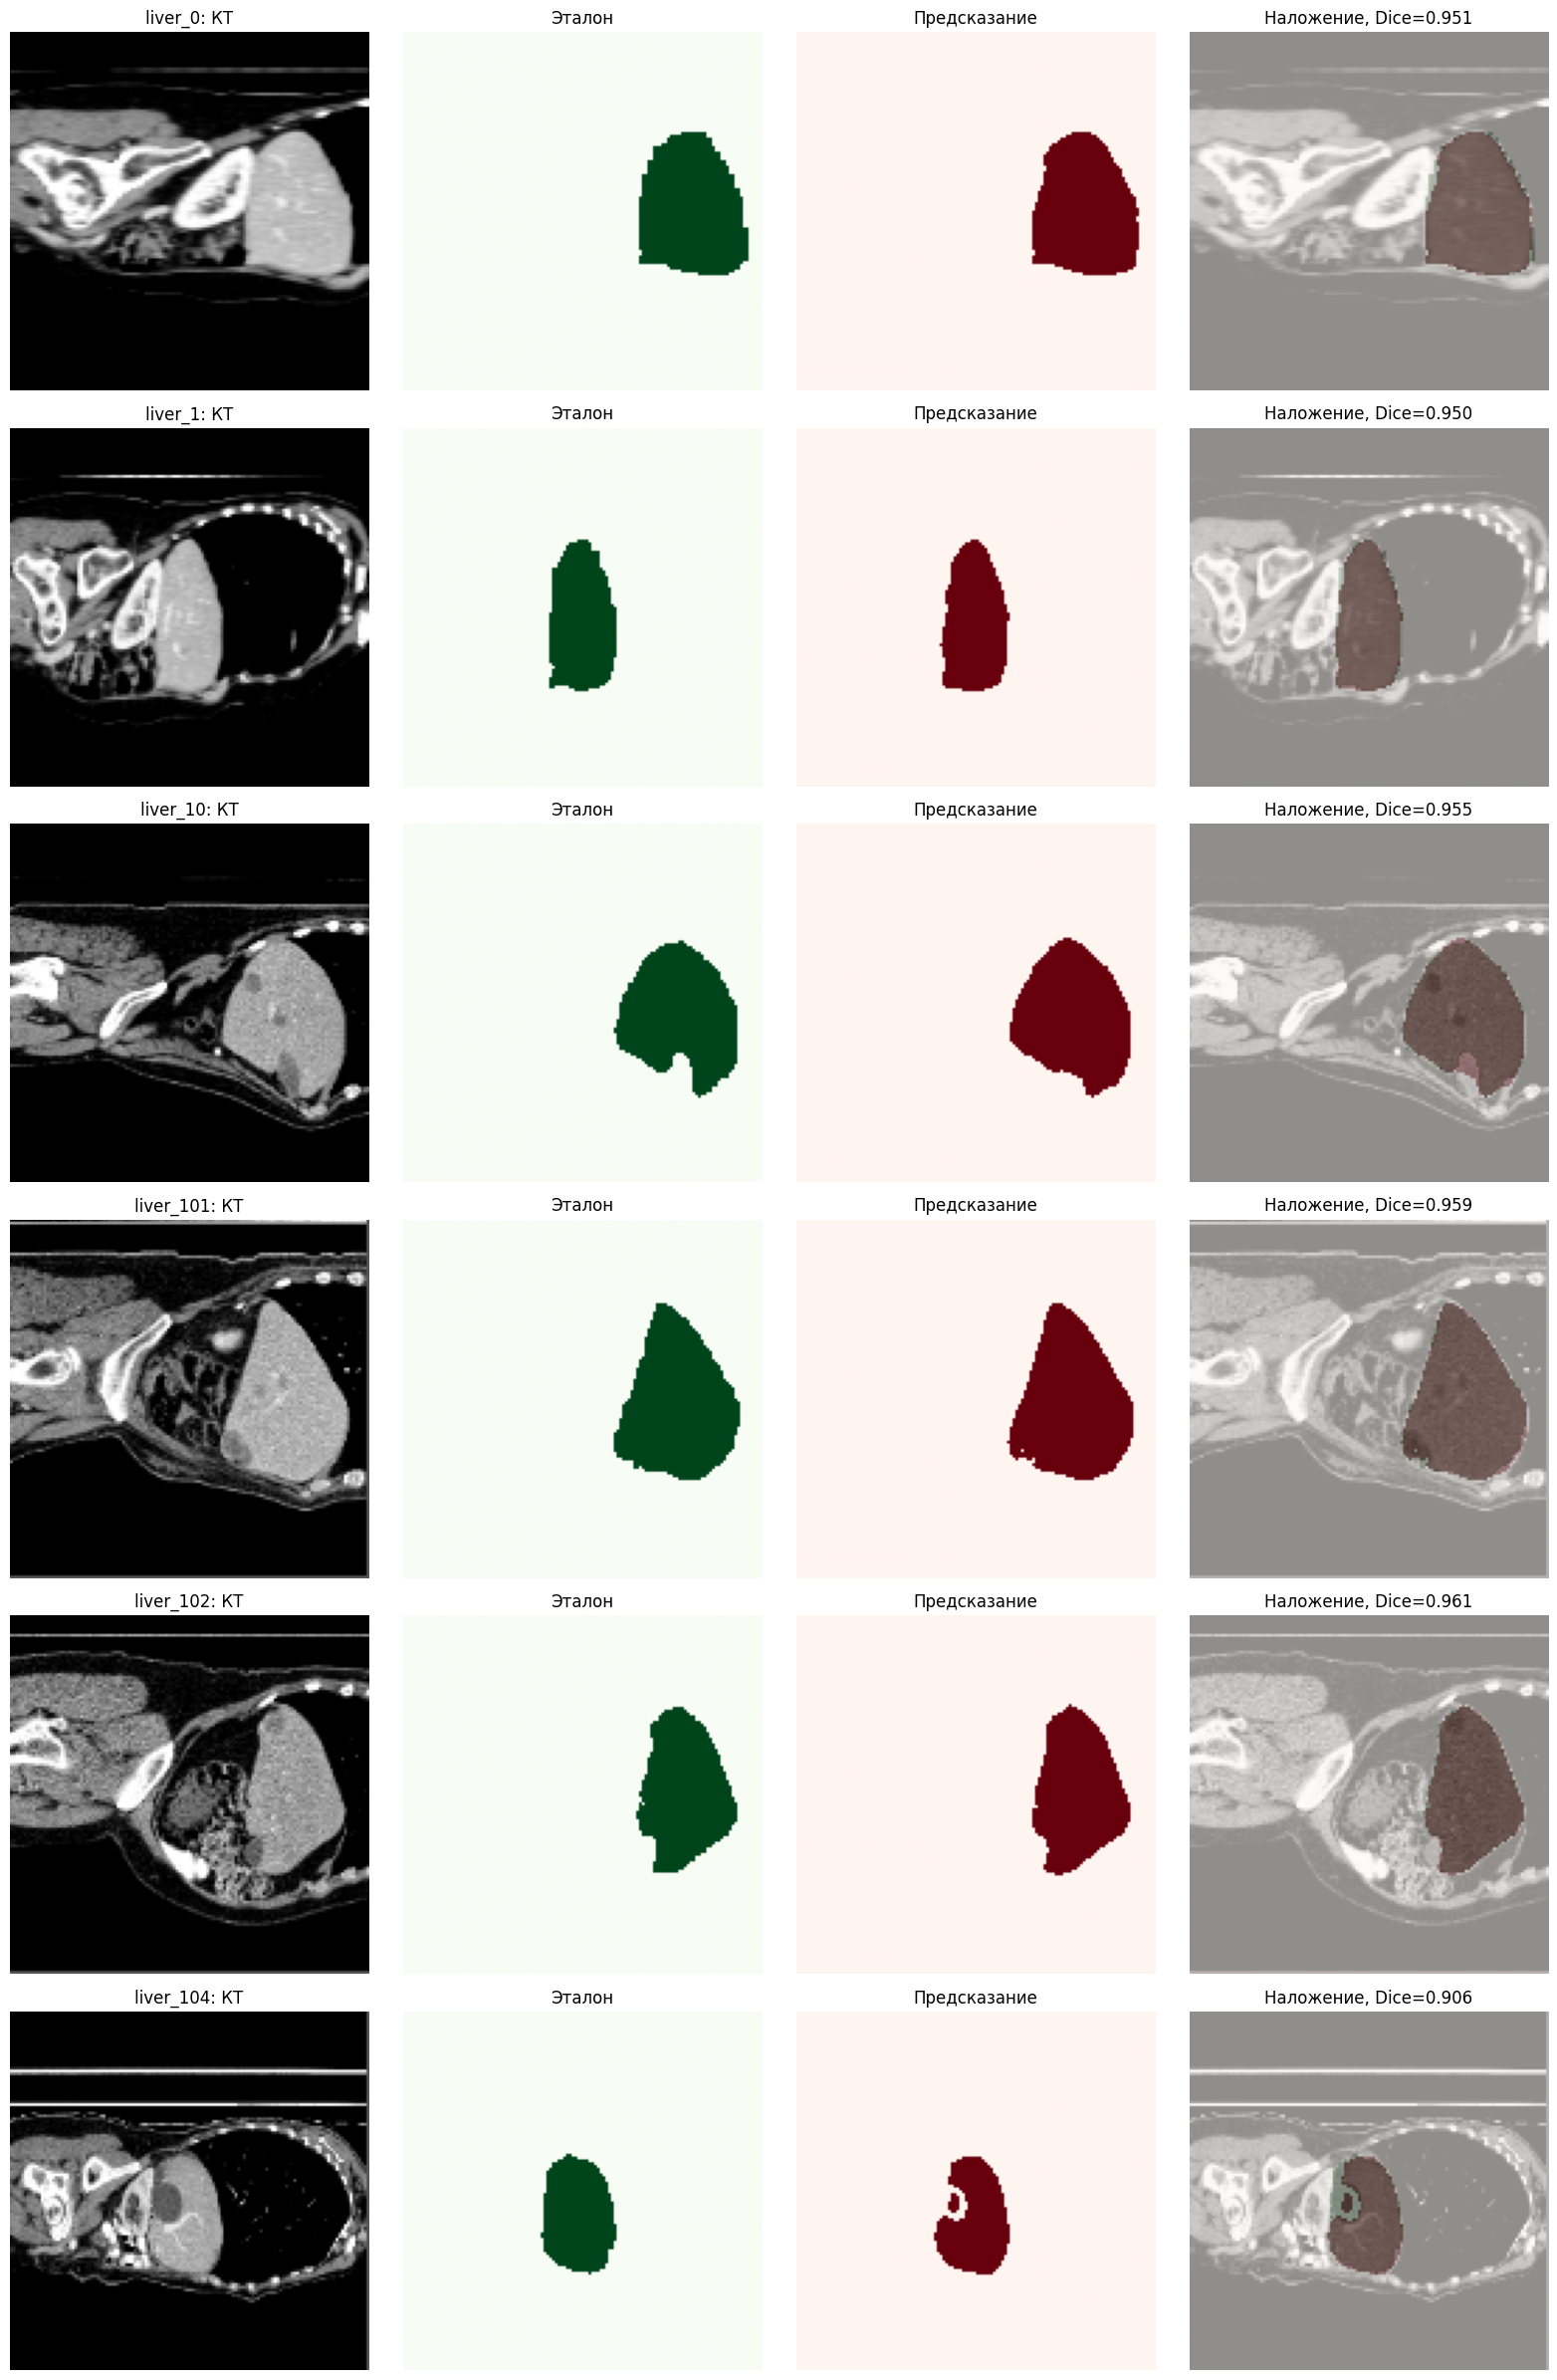

In [28]:
metrics = ["Dice", "IoU", "Precision", "Recall"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

external_df[metrics].plot(
    kind="box", ax=axes[0], grid=True
)
axes[0].set_title("Метрики на независимом датасете")
axes[0].set_ylim(0, 1.02)

axes[1].bar(
    external_df["case"],
    external_df["Dice"],
    color="steelblue"
)
axes[1].axhline(
    external_df["Dice"].mean(),
    color="red", linestyle="--",
    label=f"Средний Dice = {external_df['Dice'].mean():.3f}"
)
axes[1].set_title("Dice по пациентам")
axes[1].set_ylabel("Dice")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend()

plt.tight_layout()
plt.savefig(
    f"{RESULTS_DIR}/external_test_metrics.png",
    dpi=150
)
plt.show()

n = len(external_examples)
fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
if n == 1:
    axes = axes[None, :]

for i, (name, img, true_mask, pred) in enumerate(external_examples):
    z = int(np.argmax(true_mask.sum(axis=(1, 2))))
    d = binary_metrics(pred, true_mask)[0]

    axes[i, 0].imshow(img[z], cmap="gray")
    axes[i, 0].set_title(f"{name}: КТ")

    axes[i, 1].imshow(true_mask[z], cmap="Greens")
    axes[i, 1].set_title("Эталон")

    axes[i, 2].imshow(pred[z], cmap="Reds")
    axes[i, 2].set_title("Предсказание")

    axes[i, 3].imshow(img[z], cmap="gray")
    axes[i, 3].imshow(true_mask[z], cmap="Greens", alpha=0.35)
    axes[i, 3].imshow(pred[z], cmap="Reds", alpha=0.35)
    axes[i, 3].set_title(f"Наложение, Dice={d:.3f}")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    f"{RESULTS_DIR}/external_test_visuals.png",
    dpi=150
)
plt.show()

Пациент: liver_0
3D Dice:      0.9510
3D IoU:       0.9065
3D Precision: 0.9674
3D Recall:    0.9351
Вокселей в эталоне: 59421
Вокселей в прогнозе: 57433


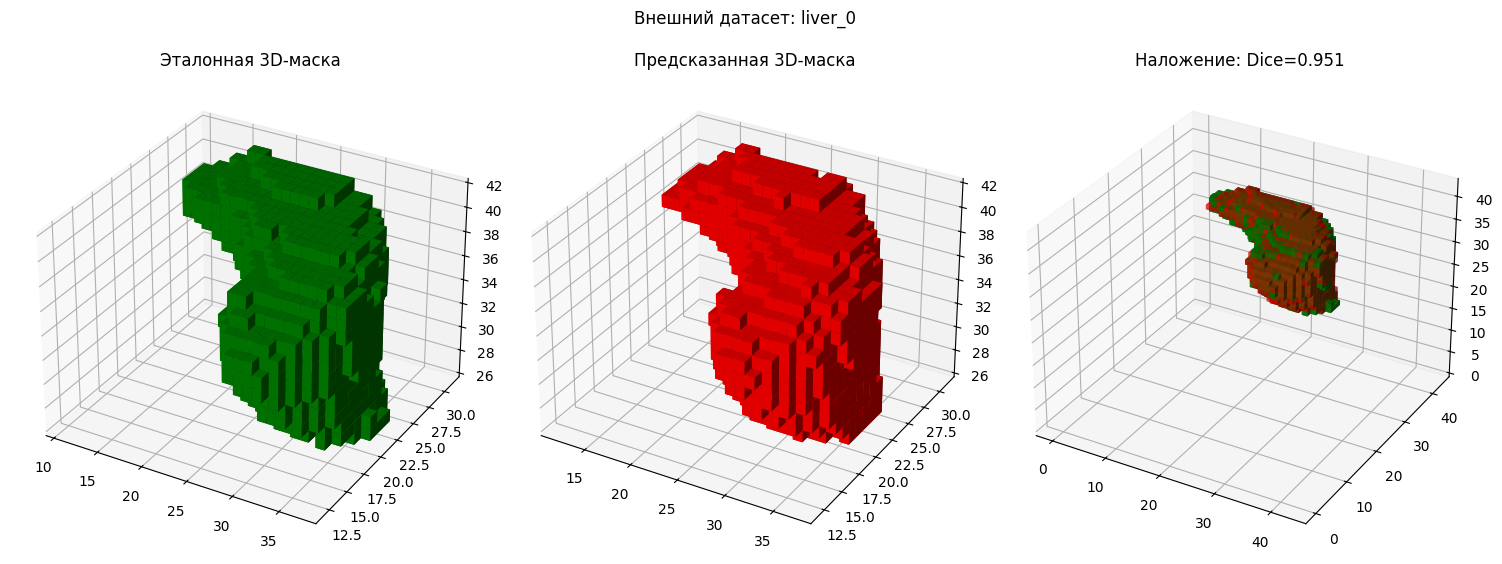

Сохранено: /content/drive/MyDrive/diplom/results_improved/external_3d_liver_0.png


In [31]:
from scipy.ndimage import binary_erosion, distance_transform_edt
from scipy.spatial.distance import directed_hausdorff
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

CASE_INDEX = 0

img_path, mask_path = external_pairs[CASE_INDEX]
case_name = file_id(img_path)

img, true_mask = preprocess_external(img_path, mask_path)
true_mask = true_mask.astype(bool)

x = torch.from_numpy(img.copy())[None, None].float().to(device)

model.eval()
with torch.inference_mode():
    logits = model(x)
    pred = (torch.sigmoid(logits)[0, 0] > 0.5).cpu().numpy()

pred = pred.astype(bool)

intersection = np.logical_and(pred, true_mask).sum()
union = np.logical_or(pred, true_mask).sum()

dice = (
    2 * intersection /
    (pred.sum() + true_mask.sum() + 1e-8)
)
iou = intersection / (union + 1e-8)

tp = np.logical_and(pred, true_mask).sum()
fp = np.logical_and(pred, ~true_mask).sum()
fn = np.logical_and(~pred, true_mask).sum()

precision = tp / (tp + fp + 1e-8)
recall = tp / (tp + fn + 1e-8)

print("Пациент:", case_name)
print(f"3D Dice:      {dice:.4f}")
print(f"3D IoU:       {iou:.4f}")
print(f"3D Precision: {precision:.4f}")
print(f"3D Recall:    {recall:.4f}")
print("Вокселей в эталоне:", true_mask.sum())
print("Вокселей в прогнозе:", pred.sum())

step = 3
gt_vis = true_mask[::step, ::step, ::step]
pred_vis = pred[::step, ::step, ::step]

fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(131, projection="3d")
ax1.voxels(
    gt_vis, facecolors="green",
    edgecolor="none", shade=True
)
ax1.set_title("Эталонная 3D-маска")

ax2 = fig.add_subplot(132, projection="3d")
ax2.voxels(
    pred_vis, facecolors="red",
    edgecolor="none", shade=True
)
ax2.set_title("Предсказанная 3D-маска")

ax3 = fig.add_subplot(133, projection="3d")
ax3.voxels(
    gt_vis, facecolors="green",
    edgecolor="none", alpha=0.8
)
ax3.voxels(
    pred_vis, facecolors="red",
    edgecolor="none", alpha=0.5
)
ax3.set_title(f"Наложение: Dice={dice:.3f}")

plt.suptitle(f"Внешний датасет: {case_name}")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR, f"external_3d_{case_name}.png"
)
plt.savefig(save_path, dpi=150)
plt.show()

print("Сохранено:", save_path)